## OpenQASM 3 and the Qiskit SDK
https://quantum.cloud.ibm.com/docs/en/qiskit/interoperate-qiskit-qasm3

In [1]:
%pip install qiskit-qasm3-import


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import qiskit.qasm3
qiskit.qasm3.load(file_name)
qiskit.qasm3.loads(program_string)

NameError: name 'file_name' is not defined

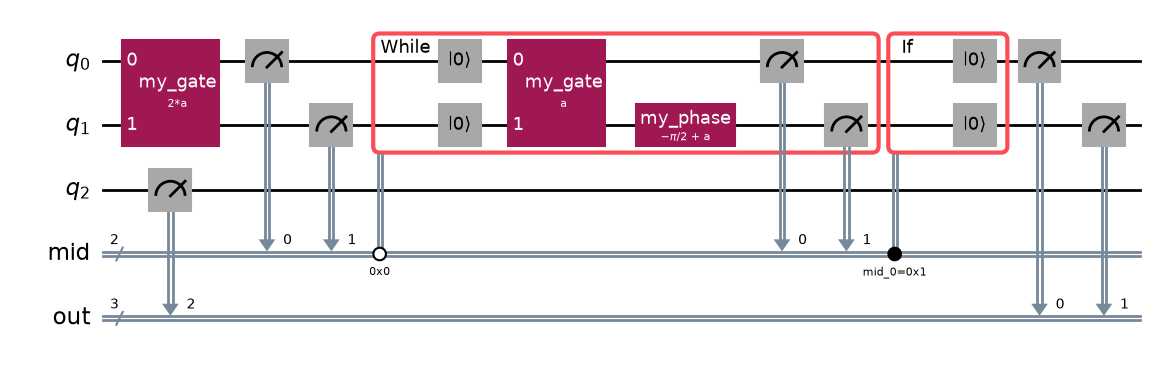

In [3]:
import qiskit.qasm3

program = """
    OPENQASM 3.0;
    include "stdgates.inc";

    input float[64] a;
    qubit[3] q;
    bit[2] mid;
    bit[3] out;

    let aliased = q[0:1];

    gate my_gate(a) c, t {
      gphase(a / 2);
      ry(a) c;
      cx c, t;
    }
    gate my_phase(a) c {
      ctrl @ inv @ gphase(a) c;
    }

    my_gate(a * 2) aliased[0], q[{1, 2}][0];
    measure q[0] -> mid[0];
    measure q[1] -> mid[1];

    while (mid == "00") {
      reset q[0];
      reset q[1];
      my_gate(a) q[0], q[1];
      my_phase(a - pi/2) q[1];
      mid[0] = measure q[0];
      mid[1] = measure q[1];
    }

    if (mid[0]) {
      let inner_alias = q[{0, 1}];
      reset inner_alias;
    }

    out = measure q;
"""
circuit = qiskit.qasm3.loads(program)
circuit.draw("mpl")

In [4]:
# Export to OpenQASM 3

from qiskit import QuantumCircuit
from qiskit.qasm3 import dumps

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

dumps(qc)

'OPENQASM 3.0;\ninclude "stdgates.inc";\nbit[2] meas;\nqubit[2] q;\nh q[0];\ncx q[0], q[1];\nbarrier q[0], q[1];\nmeas[0] = measure q[0];\nmeas[1] = measure q[1];\n'

In [5]:
from qiskit import QuantumCircuit
from qiskit.qasm3 import dump

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

f = open("my_file.txt", "w")
dump(qc, f)
f.close()